<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Classifcation/Classifcation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **6. Klasifikasi Sikap terhadap AI**

Bab ini melatih empat algoritma klasifikasi (Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression) pada 4.058 komentar YouTube tentang AI yang menggantikan pekerjaan. Label awalnya berasal dari LLM Qwen di Bab 5, lalu **ditinjau ulang** pada komentar yang paling meragukan (lihat 6.1). Alurnya: muat data, siapkan teks, bagi data, bangun fitur TF-IDF, latih empat model, bandingkan dengan validasi silang dan data uji, **tuning hyperparameter dengan Bayesian search (Optuna)**, pilih dan simpan model terbaik, lalu dua eksperimen pembanding (pengaruh kualitas label dan fitur embedding).

Karena label bersumber dari LLM, hasil bab ini mengukur seberapa baik model meniru label tersebut, bukan kebenaran mutlak.

## **6.1 Memuat Data dan Label**

Langkah ini membaca `hasil_dari_LLM_qwen_ditinjau.csv`. Berkas ini berisi dua kolom label:

- `label_qwen`: label asli hasil Qwen di Bab 5 (sama dengan `hasil_dari_LLM_qwen.csv`).
- `label_final`: label setelah ditinjau ulang. **Kolom inilah yang diprediksi model.**

**Arti label.** Yang diukur adalah **sikap terhadap AI yang menggantikan pekerjaan**, bukan nada sentimen umum:

| Label | Arti |
|---|---|
| positif | penulis **mendukung** AI, menganggapnya berguna, optimis, atau menyarankan beradaptasi dengannya |
| negatif | penulis **khawatir**, takut, marah, atau menganggap AI buruk bagi pekerja dan masyarakat |
| netral | di luar topik, lelucon tanpa sikap, pujian untuk video, pertanyaan, atau pernyataan fakta tanpa sikap |

**Catatan penting tentang arah label.** Prompt Qwen di Bab 5 menuliskan definisi sebaliknya (positif = khawatir). Namun hasil audit 200 komentar acak menunjukkan keluaran Qwen justru mengikuti arti sentimen biasa: dengan arah seperti tabel di atas label Qwen cocok sekitar 71%, sedangkan bila arahnya dibalik hanya sekitar 54%. Karena itu tabel di atas yang dipakai di seluruh bab ini.

**Peninjauan label.** Audit yang sama menemukan Qwen terlalu hati-hati: hanya sekitar 46% komentar yang khawatir dan sekitar 20% komentar yang mendukung AI yang berhasil diberi label sesuai, sisanya dilabeli netral. Maka 906 komentar yang paling meragukan (semua yang Qwen labeli positif, label negatif yang bertentangan dengan penilaian awal, dan label netral yang bertentangan dengan penilaian awal serta menyebut AI atau pekerjaan) ditinjau satu per satu memakai rubrik di atas, ditambah 200 komentar sampel audit. Total 646 baris (sekitar 16%) berubah label; sisanya tetap memakai label Qwen. Peninjau adalah Claude (sebuah LLM), **bukan anotator manusia**, sehingga `label_final` lebih baik dari label mentah tetapi tetap bukan kebenaran mutlak. Sampel audit tersimpan di `audit_label_200.csv`.

Sebaran label sangat timpang, sehingga menebak "netral" untuk semua komentar sudah menjadi **baseline** yang kuat. Model hanya berguna bila macro-F1-nya melampaui baseline ini.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Lokasi berkas: otomatis deteksi Colab vs Antigravity / Lokal
NAMA_BERKAS = 'hasil_dari_LLM_qwen_ditinjau.csv'
for lokasi in [f'/content/{NAMA_BERKAS}', f'../../datasets/{NAMA_BERKAS}',
               f'datasets/{NAMA_BERKAS}', NAMA_BERKAS]:
    if os.path.exists(lokasi):
        FILE_DATA = lokasi
        break
else:
    raise FileNotFoundError(f'{NAMA_BERKAS} tidak ditemukan. Unggah berkasnya ke /content atau taruh di folder datasets.')

df = pd.read_csv(FILE_DATA)
print(f'{len(df)} komentar dimuat dari {FILE_DATA}')

# Pastikan label lengkap dan hanya berisi tiga kategori
URUT3 = ['positif', 'negatif', 'netral']
for kolom in ['label_qwen', 'label_final']:
    df[kolom] = df[kolom].astype('string').str.strip().str.lower()
    salah = df[~df[kolom].isin(URUT3)]
    if len(salah) > 0:
        raise ValueError(f'{len(salah)} label kosong atau salah tulis di {kolom}. Contoh baris: {salah.index[:5].tolist()}')

df['label'] = df['label_final']          # target yang diprediksi model

sebaran = pd.DataFrame({
    'Qwen asli': df['label_qwen'].value_counts().reindex(URUT3),
    'Setelah ditinjau': df['label_final'].value_counts().reindex(URUT3),
})
sebaran['% Qwen asli'] = (sebaran['Qwen asli'] / len(df) * 100).round(1)
sebaran['% Setelah ditinjau'] = (sebaran['Setelah ditinjau'] / len(df) * 100).round(1)
display(sebaran)

print('Perubahan label (baris = label Qwen, kolom = label setelah ditinjau):')
display(pd.crosstab(df['label_qwen'], df['label_final']).reindex(index=URUT3, columns=URUT3))
print(f'Jumlah baris yang berubah: {(df["label_qwen"] != df["label_final"]).sum()} ({(df["label_qwen"] != df["label_final"]).mean():.1%})')

BASELINE_AKURASI = sebaran.loc['netral', 'Setelah ditinjau'] / len(df)
print(f'Baseline "tebak semua netral": akurasi {BASELINE_AKURASI:.1%}, macro-F1 sangat rendah karena positif dan negatif tidak pernah tertebak.')

4058 komentar dimuat dari ../../datasets/hasil_dari_LLM_qwen_ditinjau.csv


,Qwen asli,Setelah ditinjau,% Qwen asli,% Setelah ditinjau
positif,120,184,3.0,4.5
negatif,784,902,19.3,22.2
netral,3154,2972,77.7,73.2


Perubahan label (baris = label Qwen, kolom = label setelah ditinjau):


label_final,positif,negatif,netral
label_qwen,,,
positif,43,32,45
negatif,34,596,154
netral,107,274,2773


Jumlah baris yang berubah: 646 (15.9%)
Baseline "tebak semua netral": akurasi 73.2%, macro-F1 sangat rendah karena positif dan negatif tidak pernah tertebak.


## **6.2 Menyiapkan Teks dan Target**

Teks masukan model adalah **isi komentar saja**, tanpa judul video. Alasannya: judul yang sama muncul pada ratusan komentar sehingga model bisa "menebak" label dari judul (video yang ramai komentar khawatir) dan bukan dari isi komentar. Percobaan kami menunjukkan judul saja sudah memberi macro-F1 di atas baseline, sedangkan menambahkan judul ke komentar tidak menaikkan macro-F1; sebaliknya, tanpa judul sapaan seperti "Nonton dari Surabaya" benar diprediksi netral. Label teks diubah menjadi angka dengan `LabelEncoder` (urut abjad: negatif = 0, netral = 1, positif = 2).

In [2]:
df['text_input'] = df['comment'].fillna('')

le = LabelEncoder()
y = le.fit_transform(df['label'])
X_text = df['text_input']

print('Urutan kelas:', dict(zip(le.classes_, le.transform(le.classes_))))
df[['text_input', 'label']].head()

Urutan kelas: {'negatif': np.int64(0), 'netral': np.int64(1), 'positif': np.int64(2)}


,text_input,label
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,netral
1,Menurut saya jika semua pengusaha berpikiran s...,negatif
2,jujur ya sebagai seorang yang bekerja di bidan...,negatif
3,Gw sebagai illustrator susah bener dapet klien...,negatif
4,Niat untung -> efesiensi phk->produksi meningk...,negatif


## **6.3 Membagi Data Latih dan Data Uji**

Data dibagi 80% latih dan 20% uji secara **berstratifikasi** (proporsi tiap label dijaga). Pembagian dilakukan **sebelum** membangun fitur TF-IDF, supaya informasi dari data uji tidak ikut terpelajari saat melatih.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Data latih: {len(X_train)} | Data uji: {len(X_test)}')
tabel = pd.DataFrame({
    'Latih': pd.Series(le.inverse_transform(y_train)).value_counts(),
    'Uji': pd.Series(le.inverse_transform(y_test)).value_counts(),
}).reindex(URUT3)
display(tabel)

Data latih: 3246 | Data uji: 812


,Latih,Uji
positif,147,37
negatif,722,180
netral,2377,595


## **6.4 Membangun Fitur Teks dengan TF-IDF**

TF-IDF mengubah teks menjadi angka berdasarkan seberapa khas sebuah kata (dan pasangan dua kata) bagi sebuah komentar. Kita memakai paling banyak 5.000 fitur dengan unigram dan bigram. TF-IDF dibungkus dalam `Pipeline` bersama model, sehingga **hanya dilatih pada data latih** (juga di dalam setiap lipatan validasi silang), dan tidak pernah melihat data uji.

In [4]:
def buat_pipeline(model):
    return Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('model', model),
    ])

# Contoh bentuk fitur pada data latih (hanya untuk melihat ukurannya)
contoh = TfidfVectorizer(max_features=5000, ngram_range=(1, 2)).fit(X_train)
print(f'Jumlah fitur TF-IDF: {len(contoh.vocabulary_)}')
print('Contoh 15 fitur:', list(contoh.get_feature_names_out()[:15]))

Jumlah fitur TF-IDF: 5000
Contoh 15 fitur: ['000', '10', '10 000', '10 tahun', '10 years', '100', '1000', '11', '12', '13', '14', '15', '18', '19', '20']


## **6.5 Menangani Kelas yang Timpang**

Kelas positif hanya sekitar 5% dari data. Tanpa penanganan, model cenderung menebak "netral" untuk semuanya. Kita memakai `class_weight='balanced'` pada Decision Tree, Random Forest, dan Logistic Regression, yang membuat kesalahan pada kelas kecil dihukum lebih berat. Naïve Bayes memakai `ComplementNB`, varian yang memang dirancang untuk data teks yang timpang. Cara ini dipilih daripada SMOTE karena tidak membuat data buatan dan tidak perlu mereduksi dimensi fitur.

In [5]:
bobot = len(y_train) / (len(le.classes_) * np.bincount(y_train))
print('Bobot kelas (class_weight="balanced"):')
display(pd.DataFrame({'Kelas': le.classes_, 'Bobot': bobot.round(2)}).set_index('Kelas'))

Bobot kelas (class_weight="balanced"):


,Bobot
Kelas,
negatif,1.50
netral,0.46
positif,7.36


## **6.6 Melatih Empat Model**

| Model | Catatan |
|---|---|
| Decision Tree | `class_weight='balanced'`, kedalaman dibatasi agar tidak menghafal data latih |
| Naïve Bayes | `ComplementNB`, cocok untuk teks dengan kelas timpang |
| Random Forest | 200 pohon, `class_weight='balanced_subsample'`, kedalaman dibatasi |
| Logistic Regression | `class_weight='balanced'` |

Semua memakai parameter sederhana. Tujuannya membandingkan algoritma, bukan mencari parameter terbaik.

In [6]:
MODELS = {
    'Decision Tree': DecisionTreeClassifier(max_depth=20, class_weight='balanced', random_state=42),
    'Naïve Bayes': ComplementNB(),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=30, class_weight='balanced_subsample',
                                            random_state=42, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
}

pipelines = {nama: buat_pipeline(model) for nama, model in MODELS.items()}
for nama, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
print('✅ Keempat model selesai dilatih.')

✅ Keempat model selesai dilatih.


## **6.7 Validasi Silang pada Data Latih**

Satu kali pembagian data bisa kebetulan menguntungkan atau merugikan sebuah model, apalagi kelas positif hanya punya sedikit contoh. Validasi silang berstratifikasi 5 lipatan melatih dan menguji tiap model lima kali pada potongan data latih yang berbeda. Hasilnya dilaporkan sebagai rata-rata ± simpangan baku. **Macro-F1** dipakai sebagai ukuran utama karena memperlakukan ketiga kelas sama pentingnya.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for nama, model in MODELS.items():
    hasil = cross_validate(buat_pipeline(model), X_train, y_train, cv=cv,
                           scoring={'akurasi': 'accuracy', 'macro_f1': 'f1_macro'}, n_jobs=-1)
    baris.append({
        'Model': nama,
        'Akurasi (rata-rata)': round(hasil['test_akurasi'].mean(), 3),
        'Macro-F1 (rata-rata)': round(hasil['test_macro_f1'].mean(), 3),
        'Macro-F1 (simpangan)': round(hasil['test_macro_f1'].std(), 3),
    })
df_cv = pd.DataFrame(baris).set_index('Model').sort_values('Macro-F1 (rata-rata)', ascending=False)
display(df_cv)

,Akurasi (rata-rata),Macro-F1 (rata-rata),Macro-F1 (simpangan)
Model,,,
Logistic Regression,0.721,0.522,0.030
Decision Tree,0.657,0.433,0.015
Naïve Bayes,0.697,0.423,0.017
Random Forest,0.740,0.409,0.011


## **6.8 Evaluasi pada Data Uji**

Data uji hanya dipakai sekali di sini. Tabel pertama membandingkan akurasi dan macro-F1 keempat model dengan baseline "tebak semua netral". Tabel kedua merinci precision, recall, dan F1 tiap kelas, lalu confusion matrix menunjukkan kelas mana yang tertukar.

Cara membaca: akurasi bisa tinggi hanya karena kelas netral dominan, jadi bandingkan selalu dengan baseline dan lihat **macro-F1** serta **recall kelas positif dan negatif**.

1. Perbandingan dengan baseline


,Akurasi,Macro-F1
Model,,
Baseline: tebak semua netral,0.733,0.282
Decision Tree,0.665,0.455
Naïve Bayes,0.698,0.407
Random Forest,0.762,0.447
Logistic Regression,0.718,0.525



2. Precision, recall, dan F1 tiap kelas


,P positif,R positif,F1 positif,P negatif,R negatif,F1 negatif,P netral,R netral,F1 netral
Model,,,,,,,,,
Decision Tree,0.104,0.135,0.118,0.394,0.556,0.461,0.853,0.731,0.787
Naïve Bayes,0.000,0.000,0.000,0.420,0.406,0.412,0.789,0.830,0.809
Random Forest,0.000,0.000,0.000,0.534,0.439,0.482,0.813,0.908,0.858
Logistic Regression,0.237,0.243,0.240,0.459,0.583,0.513,0.861,0.788,0.823



3. Confusion matrix (baris = label sebenarnya, kolom = tebakan model)


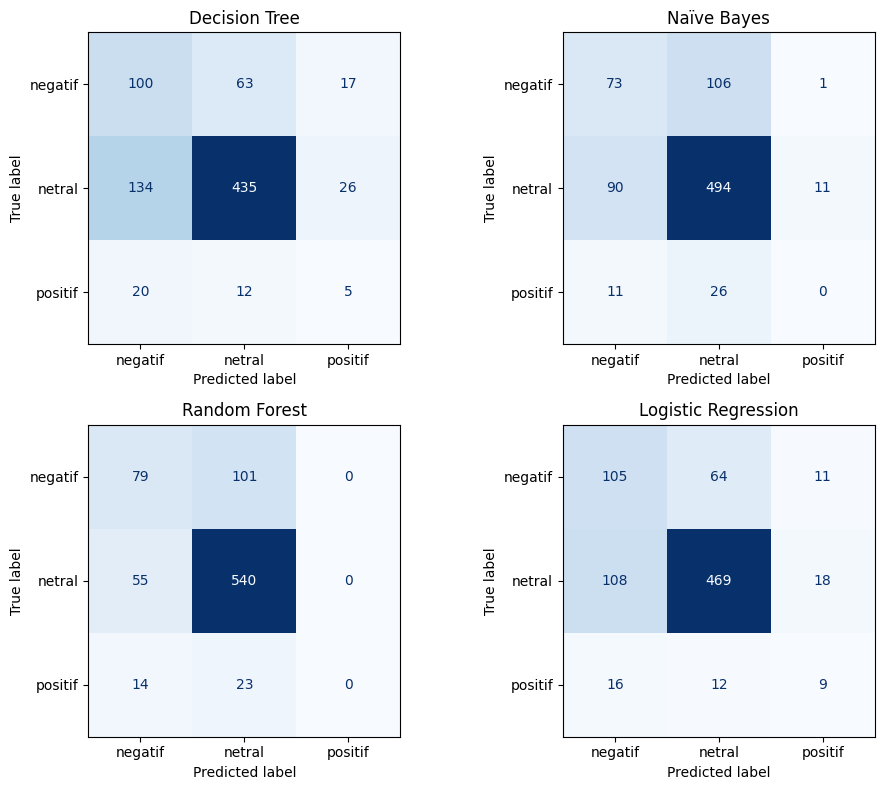

In [8]:
y_pred = {nama: pipe.predict(X_test) for nama, pipe in pipelines.items()}

# Baseline: tebak semua netral
y_base = np.full(len(y_test), le.transform(['netral'])[0])

baris = [{'Model': 'Baseline: tebak semua netral',
          'Akurasi': round(accuracy_score(y_test, y_base), 3),
          'Macro-F1': round(f1_score(y_test, y_base, average='macro', zero_division=0), 3)}]
for nama, pred in y_pred.items():
    baris.append({'Model': nama,
                  'Akurasi': round(accuracy_score(y_test, pred), 3),
                  'Macro-F1': round(f1_score(y_test, pred, average='macro', zero_division=0), 3)})
df_uji = pd.DataFrame(baris).set_index('Model')
print('1. Perbandingan dengan baseline')
display(df_uji)

print('\n2. Precision, recall, dan F1 tiap kelas')
rinci = []
for nama, pred in y_pred.items():
    lap = classification_report(y_test, pred, target_names=le.classes_, output_dict=True, zero_division=0)
    baris_m = {'Model': nama}
    for kelas in URUT3:
        baris_m[f'P {kelas}'] = round(lap[kelas]['precision'], 3)
        baris_m[f'R {kelas}'] = round(lap[kelas]['recall'], 3)
        baris_m[f'F1 {kelas}'] = round(lap[kelas]['f1-score'], 3)
    rinci.append(baris_m)
display(pd.DataFrame(rinci).set_index('Model'))

print('\n3. Confusion matrix (baris = label sebenarnya, kolom = tebakan model)')
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (nama, pred) in zip(axes.ravel(), y_pred.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=le.classes_).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(nama)
plt.tight_layout()
plt.show()

## **6.9 Memeriksa Overfitting**

Model dikatakan overfitting bila jauh lebih bagus pada data latih daripada data uji. Pemeriksaan ini memakai **macro-F1 pada data latih asli (tanpa data buatan)** dan macro-F1 pada data uji, sehingga keduanya sebanding. Selisih lebih dari 0,15 ditandai sebagai overfitting.

In [9]:
baris = []
for nama, pipe in pipelines.items():
    f1_latih = f1_score(y_train, pipe.predict(X_train), average='macro', zero_division=0)
    f1_uji = f1_score(y_test, y_pred[nama], average='macro', zero_division=0)
    selisih = f1_latih - f1_uji
    baris.append({'Model': nama, 'Macro-F1 latih': round(f1_latih, 3), 'Macro-F1 uji': round(f1_uji, 3),
                  'Selisih': round(selisih, 3), 'Status': 'Overfitting ⚠️' if selisih > 0.15 else 'Wajar ✅'})
display(pd.DataFrame(baris).set_index('Model'))

,Macro-F1 latih,Macro-F1 uji,Selisih,Status
Model,,,,
Decision Tree,0.866,0.455,0.411,Overfitting ⚠️
Naïve Bayes,0.768,0.407,0.360,Overfitting ⚠️
Random Forest,0.954,0.447,0.507,Overfitting ⚠️
Logistic Regression,0.866,0.525,0.340,Overfitting ⚠️


## **6.10 Tuning Hyperparameter dengan Bayesian Search (Optuna)**

Sampai 6.9 semua model memakai parameter sederhana. Di sini parameter dicari secara sistematis dengan **Bayesian search** memakai [Optuna](https://optuna.org) (sampler TPE). Berbeda dengan pencarian acak, Bayesian search memilih percobaan berikutnya berdasarkan hasil percobaan sebelumnya, sehingga lebih hemat percobaan.

Aturan supaya adil dan tidak bocor:

- Tuning **hanya memakai data latih**. Skor tiap percobaan adalah rata-rata macro-F1 validasi silang 5 lipatan pada data latih. Data uji tidak disentuh sampai evaluasi akhir.
- TF-IDF ikut dituning (jumlah fitur, unigram atau bigram, `min_df`) karena berada di dalam `Pipeline`, jadi dilatih ulang di setiap lipatan.
- Skor terbaik hasil tuning cenderung sedikit optimistis karena diambil dari banyak percobaan; ukuran yang jujur adalah macro-F1 pada data uji.

Sel pertama memasang Optuna bila belum ada. Sel kedua menjalankan pencarian (beberapa menit, paling lama di Random Forest).

In [10]:
try:
    import optuna
except ImportError:
    !pip install -q optuna
    import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
print('Optuna versi', optuna.__version__)

Optuna versi 5.0.0



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\ACER\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
def bangun_pipeline_tuning(nama, p):
    """Membuat pipeline dari satu set parameter hasil tuning."""
    tfidf = TfidfVectorizer(max_features=p['max_features'],
                            ngram_range=(1, 1) if p['ngram'] == '1-1' else (1, 2),
                            min_df=p['min_df'])
    if nama == 'Logistic Regression':
        model = LogisticRegression(C=p['C'], max_iter=1000, class_weight='balanced', random_state=42)
    elif nama == 'Naïve Bayes':
        model = ComplementNB(alpha=p['alpha'], norm=p['norm'])
    elif nama == 'Decision Tree':
        model = DecisionTreeClassifier(max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'],
                                       class_weight='balanced', random_state=42)
    else:
        model = RandomForestClassifier(n_estimators=p['n_estimators'], max_depth=p['max_depth'],
                                       min_samples_leaf=p['min_samples_leaf'], max_features=p['max_features_rf'],
                                       class_weight='balanced_subsample', random_state=42, n_jobs=-1)
    return Pipeline([('tfidf', tfidf), ('model', model)])


def usulkan_parameter(nama, trial):
    p = {
        'max_features': trial.suggest_categorical('max_features', [3000, 5000, 8000, 12000]),
        'ngram': trial.suggest_categorical('ngram', ['1-1', '1-2']),
        'min_df': trial.suggest_int('min_df', 1, 3),
    }
    if nama == 'Logistic Regression':
        p['C'] = trial.suggest_float('C', 0.05, 20, log=True)
    elif nama == 'Naïve Bayes':
        p['alpha'] = trial.suggest_float('alpha', 0.01, 3, log=True)
        p['norm'] = trial.suggest_categorical('norm', [False, True])
    elif nama == 'Decision Tree':
        p['max_depth'] = trial.suggest_int('max_depth', 3, 30)
        p['min_samples_leaf'] = trial.suggest_int('min_samples_leaf', 1, 10)
    else:
        p['n_estimators'] = trial.suggest_int('n_estimators', 100, 400, step=50)
        p['max_depth'] = trial.suggest_int('max_depth', 5, 40)
        p['min_samples_leaf'] = trial.suggest_int('min_samples_leaf', 1, 5)
        p['max_features_rf'] = trial.suggest_categorical('max_features_rf', ['sqrt', 'log2'])
    return p


JUMLAH_PERCOBAAN = {'Decision Tree': 30, 'Naïve Bayes': 40, 'Random Forest': 15, 'Logistic Regression': 30}
cv_tuning = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

studi = {}
for nama, n_percobaan in JUMLAH_PERCOBAAN.items():
    def objective(trial, nama=nama):
        p = usulkan_parameter(nama, trial)
        skor = cross_val_score(bangun_pipeline_tuning(nama, p), X_train, y_train,
                               cv=cv_tuning, scoring='f1_macro', n_jobs=-1)
        return skor.mean()

    studi[nama] = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    studi[nama].optimize(objective, n_trials=n_percobaan)
    print(f'{nama:20s} {n_percobaan:2d} percobaan | macro-F1 CV terbaik = {studi[nama].best_value:.3f}')

Decision Tree        30 percobaan | macro-F1 CV terbaik = 0.453
Naïve Bayes          40 percobaan | macro-F1 CV terbaik = 0.462
Random Forest        15 percobaan | macro-F1 CV terbaik = 0.492
Logistic Regression  30 percobaan | macro-F1 CV terbaik = 0.525


### Hasil tuning

Tabel pertama membandingkan model **sebelum dan sesudah tuning**: macro-F1 validasi silang (data latih), macro-F1 data uji, dan selisih macro-F1 latih dan uji untuk memeriksa overfitting. Tabel kedua memuat parameter terbaik. Grafik menunjukkan skor terbaik yang dicapai seiring bertambahnya percobaan; bila garisnya sudah mendatar, menambah percobaan tidak akan banyak membantu.

1. Sebelum vs sesudah tuning


,F1 CV sebelum,F1 CV sesudah,F1 uji sebelum,F1 uji sesudah,Selisih latih-uji sesudah,Perubahan F1 uji
Model,,,,,,
Decision Tree,0.433,0.453,0.455,0.446,0.312,-0.009
Naïve Bayes,0.423,0.462,0.407,0.435,0.257,0.028
Random Forest,0.409,0.492,0.447,0.506,0.318,0.059
Logistic Regression,0.522,0.525,0.525,0.532,0.398,0.007



2. Parameter terbaik


,Parameter terbaik
Model,
Decision Tree,"max_features=12000, ngram=1-1, min_df=3, max_depth=12, min_samples_leaf=1"
Naïve Bayes,"max_features=3000, ngram=1-2, min_df=3, alpha=0.15, norm=True"
Random Forest,"max_features=5000, ngram=1-1, min_df=2, n_estimators=200, max_depth=39, min_samples_leaf=4, max_features_rf=sqrt"
Logistic Regression,"max_features=12000, ngram=1-2, min_df=2, C=1.48"



3. Skor terbaik per jumlah percobaan


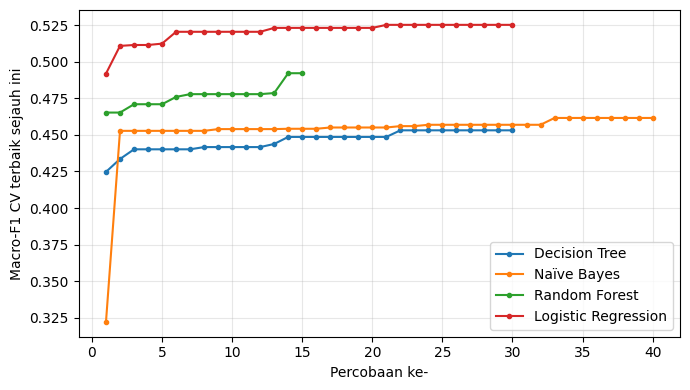

In [12]:
pipelines_tuning = {}
baris, parameter_terbaik = [], []
for nama, study in studi.items():
    pipe = bangun_pipeline_tuning(nama, study.best_params).fit(X_train, y_train)
    pipelines_tuning[nama] = pipe
    pred = pipe.predict(X_test)
    f1_uji_t = f1_score(y_test, pred, average='macro', zero_division=0)
    f1_latih_t = f1_score(y_train, pipe.predict(X_train), average='macro', zero_division=0)
    baris.append({
        'Model': nama,
        'F1 CV sebelum': df_cv.loc[nama, 'Macro-F1 (rata-rata)'],
        'F1 CV sesudah': round(study.best_value, 3),
        'F1 uji sebelum': df_uji.loc[nama, 'Macro-F1'],
        'F1 uji sesudah': round(f1_uji_t, 3),
        'Selisih latih-uji sesudah': round(f1_latih_t - f1_uji_t, 3),
    })
    parameter_terbaik.append({'Model': nama, 'Parameter terbaik': ', '.join(f'{k}={v:.3g}' if isinstance(v, float) else f'{k}={v}'
                                                                                   for k, v in study.best_params.items())})

df_tuning = pd.DataFrame(baris).set_index('Model')
df_tuning['Perubahan F1 uji'] = (df_tuning['F1 uji sesudah'] - df_tuning['F1 uji sebelum']).round(3)
print('1. Sebelum vs sesudah tuning')
display(df_tuning)

print('\n2. Parameter terbaik')
pd.set_option('display.max_colwidth', 200)
display(pd.DataFrame(parameter_terbaik).set_index('Model'))

print('\n3. Skor terbaik per jumlah percobaan')
plt.figure(figsize=(7, 4))
for nama, study in studi.items():
    nilai = [t.value for t in study.trials]
    plt.plot(range(1, len(nilai) + 1), np.maximum.accumulate(nilai), marker='o', markersize=3, label=nama)
plt.xlabel('Percobaan ke-')
plt.ylabel('Macro-F1 CV terbaik sejauh ini')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **6.11 Memilih Model Terbaik**

Kandidatnya delapan: empat model dasar (6.6) dan empat model hasil tuning (6.10). Model terbaik dipilih dari **macro-F1 validasi silang pada data latih**, bukan dari data uji, supaya data uji tetap murni untuk melaporkan hasil akhir. Akurasi tidak dipakai karena dikuasai kelas netral. Teks di bawah dibuat otomatis dari hasil, supaya selalu cocok dengan tabel.

In [13]:
kandidat = {}
for nama in MODELS:
    kandidat[f'{nama} (dasar)'] = {'pipe': pipelines[nama], 'pred': y_pred[nama],
                                   'f1_cv': df_cv.loc[nama, 'Macro-F1 (rata-rata)']}
    kandidat[f'{nama} (tuning)'] = {'pipe': pipelines_tuning[nama], 'pred': pipelines_tuning[nama].predict(X_test),
                                    'f1_cv': studi[nama].best_value}

tabel_kandidat = pd.DataFrame({
    nama: {'Macro-F1 CV (latih)': round(v['f1_cv'], 3),
           'Macro-F1 uji': round(f1_score(y_test, v['pred'], average='macro', zero_division=0), 3),
           'Akurasi uji': round(accuracy_score(y_test, v['pred']), 3)}
    for nama, v in kandidat.items()
}).T.sort_values('Macro-F1 CV (latih)', ascending=False)
display(tabel_kandidat)

model_terbaik = tabel_kandidat.index[0]
pipe_terbaik = kandidat[model_terbaik]['pipe']
pred_terbaik = kandidat[model_terbaik]['pred']
f1_terbaik = tabel_kandidat.loc[model_terbaik, 'Macro-F1 uji']
akurasi_terbaik = tabel_kandidat.loc[model_terbaik, 'Akurasi uji']
f1_baseline = df_uji.loc['Baseline: tebak semua netral', 'Macro-F1']

print(f'Model terbaik berdasarkan macro-F1 validasi silang: {model_terbaik}')
print(f'  Pada data uji: macro-F1 {f1_terbaik:.3f} (baseline {f1_baseline:.3f}), akurasi {akurasi_terbaik:.1%} (baseline {BASELINE_AKURASI:.1%})')

lap = classification_report(y_test, pred_terbaik, target_names=le.classes_, output_dict=True, zero_division=0)
for kelas in URUT3:
    print(f'  Recall {kelas}: {lap[kelas]["recall"]:.1%}')

if akurasi_terbaik < BASELINE_AKURASI:
    print('\nCatatan: akurasi model masih di bawah baseline karena model sengaja dilatih agar tidak mengabaikan kelas kecil. '
          'Ukuran yang adil adalah macro-F1 dan recall per kelas.')

,Macro-F1 CV (latih),Macro-F1 uji,Akurasi uji
Logistic Regression (tuning),0.525,0.532,0.734
Logistic Regression (dasar),0.522,0.525,0.718
Random Forest (tuning),0.492,0.506,0.734
Naïve Bayes (tuning),0.462,0.435,0.611
Decision Tree (tuning),0.453,0.446,0.669
Decision Tree (dasar),0.433,0.455,0.665
Naïve Bayes (dasar),0.423,0.407,0.698
Random Forest (dasar),0.409,0.447,0.762


Model terbaik berdasarkan macro-F1 validasi silang: Logistic Regression (tuning)
  Pada data uji: macro-F1 0.532 (baseline 0.282), akurasi 73.4% (baseline 73.2%)
  Recall positif: 18.9%
  Recall negatif: 58.3%
  Recall netral: 81.3%


## **6.12 Menyimpan Model Terbaik**

Model terbaik disimpan bersama pipeline TF-IDF-nya dan `LabelEncoder`, sehingga bisa dipakai langsung untuk memprediksi teks baru.

In [14]:
artefak = {'pipeline': pipe_terbaik, 'label_encoder': le, 'nama_model': model_terbaik}
NAMA_FILE_MODEL = 'model_sikap_ai_terbaik.pkl'
joblib.dump(artefak, NAMA_FILE_MODEL)
print(f'✅ Model {model_terbaik} disimpan ke {NAMA_FILE_MODEL}')

✅ Model Logistic Regression (tuning) disimpan ke model_sikap_ai_terbaik.pkl


## **6.13 Memprediksi Teks Baru**

Sel ini memuat model yang tersimpan lalu memprediksi komentar. Ingat arti label: **positif = mendukung AI/menganggapnya berguna, negatif = khawatir/menganggap AI buruk bagi pekerjaan, netral = di luar topik atau tidak ada sikap**.

Bagian pertama memakai 10 komentar acak dari data uji, lengkap dengan label sebenarnya, supaya terlihat apa adanya seberapa sering model benar. Bagian kedua mencoba beberapa komentar buatan sendiri sebagai demonstrasi cara memakai model.

In [15]:
ARTI_LABEL = {'positif': 'mendukung AI / menganggapnya berguna',
              'negatif': 'khawatir / menganggap AI buruk bagi pekerjaan',
              'netral': 'di luar topik / tidak ada sikap'}

dimuat = joblib.load(NAMA_FILE_MODEL)
pipe_dimuat, le_dimuat = dimuat['pipeline'], dimuat['label_encoder']

# 1. Sepuluh komentar acak dari data uji (label sebenarnya vs tebakan model)
acak = X_test.sample(10, random_state=42)
tabel = pd.DataFrame({
    'komentar': acak.str.slice(0, 90),
    'label sebenarnya': le_dimuat.inverse_transform(y_test[X_test.index.get_indexer(acak.index)]),
    'tebakan model': le_dimuat.inverse_transform(pipe_dimuat.predict(acak)),
})
tabel['benar?'] = np.where(tabel['label sebenarnya'] == tabel['tebakan model'], '✅', '❌')
pd.set_option('display.max_colwidth', 100)
display(tabel.reset_index(drop=True))

# 2. Contoh komentar buatan sendiri (cara memakai model)
contoh_baru = [
    'Saya takut pekerjaan saya digantikan AI dalam beberapa tahun lagi.',
    'AI ini sangat membantu dan mempermudah pekerjaan manusia!',
    'Nonton dari Surabaya, halo semuanya.',
]
prediksi = le_dimuat.inverse_transform(pipe_dimuat.predict(contoh_baru))
print('\nContoh komentar buatan sendiri:')
for teks, label in zip(contoh_baru, prediksi):
    print(f'{label.upper():8s} ({ARTI_LABEL[label]})  <-  {teks}')

,komentar,label sebenarnya,tebakan model,benar?
0,"Hmmm...GREAT IDEA! Now if you excuse me, my robot is calling me for my daily session of cu",netral,netral,✅
1,I’m trying to be a welder.,netral,netral,✅
2,It’s outsourcing. 100 billion a year leaving the UK. AI isn’t taking jobs. So dumb.,netral,netral,✅
3,I live in utter bliss for the 80-100 years im on this earth and am thankful for the luxury,netral,netral,✅
4,"ya dirampok lah sama manusia jok. 😅 semakin banyak orang miskin, maka suatu saat orang kay",negatif,netral,❌
5,"Menurut saya AI ibarat buah simalakama, makin sering di gunakan maka kehidupan manusia ber",negatif,negatif,✅
6,exactly. It would be up to governments to provide it. Like fk these AI companies will be s,negatif,positif,❌
7,Bang coba bahas juga perusaan ai yang merusak buku langka dan isu bahwa gara-gara perusaan,netral,netral,✅
8,"so many way to discard that... I'll just take one. When you are a Junior, you need to lear",negatif,negatif,✅
9,"At this point of time UK should stop funding other countries, no support/funds for illegal",netral,negatif,❌



Contoh komentar buatan sendiri:
NEGATIF  (khawatir / menganggap AI buruk bagi pekerjaan)  <-  Saya takut pekerjaan saya digantikan AI dalam beberapa tahun lagi.
POSITIF  (mendukung AI / menganggapnya berguna)  <-  AI ini sangat membantu dan mempermudah pekerjaan manusia!
NETRAL   (di luar topik / tidak ada sikap)  <-  Nonton dari Surabaya, halo semuanya.


## **6.14 Eksperimen: Pengaruh Kualitas Label**

Bagian ini menjawab pertanyaan "apakah peninjauan label benar-benar membantu?" dengan pembagian data yang **sama persis** seperti 6.3, dan model dasar yang sama seperti 6.6. Tiga kondisi dibandingkan:

| Kondisi | Dilatih dengan | Diuji terhadap |
|---|---|---|
| A | label Qwen asli | label Qwen asli |
| B | label Qwen asli | label setelah ditinjau |
| C | label setelah ditinjau | label setelah ditinjau |

Perbandingan **B dengan C** paling adil karena keduanya diuji terhadap patokan yang sama; selisihnya menunjukkan manfaat melatih dengan label yang lebih bersih. Kondisi A hanya untuk melihat angka versi awal. Karena patokan A dan C berbeda, angkanya tidak boleh dibandingkan langsung.

In [16]:
idx_latih, idx_uji = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df['label_final'])
assert set(idx_latih) == set(X_train.index), 'Pembagian data harus sama dengan 6.3'

def f1_makro_kondisi(model, kolom_latih, kolom_uji):
    pipe = buat_pipeline(clone(model)).fit(df.loc[idx_latih, 'text_input'], df.loc[idx_latih, kolom_latih])
    pred = pipe.predict(df.loc[idx_uji, 'text_input'])
    return f1_score(df.loc[idx_uji, kolom_uji], pred, average='macro', zero_division=0)

baris = []
for nama, model in MODELS.items():
    baris.append({
        'Model': nama,
        'A: Qwen → Qwen': round(f1_makro_kondisi(model, 'label_qwen', 'label_qwen'), 3),
        'B: Qwen → ditinjau': round(f1_makro_kondisi(model, 'label_qwen', 'label_final'), 3),
        'C: ditinjau → ditinjau': round(f1_makro_kondisi(model, 'label_final', 'label_final'), 3),
    })
df_label = pd.DataFrame(baris).set_index('Model')
df_label['Manfaat (C - B)'] = (df_label['C: ditinjau → ditinjau'] - df_label['B: Qwen → ditinjau']).round(3)
print('Macro-F1 pada data uji')
display(df_label)

Macro-F1 pada data uji


,A: Qwen → Qwen,B: Qwen → ditinjau,C: ditinjau → ditinjau,Manfaat (C - B)
Model,,,,
Decision Tree,0.435,0.460,0.455,-0.005
Naïve Bayes,0.417,0.396,0.407,0.011
Random Forest,0.379,0.379,0.447,0.068
Logistic Regression,0.497,0.445,0.525,0.080


## **6.15 Eksperimen Tambahan: Fitur Embedding Multibahasa**

TF-IDF hanya menghitung kata, sehingga tidak tahu bahwa "takut kehilangan kerja" dan "khawatir di-PHK" bermakna mirip, atau bahwa sebuah kalimat bernada sindiran. **Embedding** kalimat dari model bahasa yang sudah dilatih sebelumnya (di sini `intfloat/multilingual-e5-small`, mendukung bahasa Indonesia dan Inggris) mengubah tiap komentar menjadi vektor yang menangkap makna. Vektor itu lalu dipakai oleh Logistic Regression yang sama.

Ini **eksperimen pembanding**, bukan pengganti pipeline utama. Sel pertama mengunduh model (±120 MB) dan menghitung embedding; di Colab CPU memakan beberapa menit, dengan GPU jauh lebih cepat. Pembagian data tetap sama dengan 6.3.

In [17]:
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    !pip install -q sentence-transformers
    from sentence_transformers import SentenceTransformer

try:
    import torch
    perangkat = 'cuda' if torch.cuda.is_available() else 'cpu'
except ImportError:
    perangkat = 'cpu'

NAMA_EMBEDDING = 'intfloat/multilingual-e5-small'
encoder = SentenceTransformer(NAMA_EMBEDDING, device=perangkat)
encoder.max_seq_length = 256


def hitung_embedding(teks):
    # model e5 mewajibkan awalan "query: " pada setiap teks
    return encoder.encode(['query: ' + t for t in teks], batch_size=64,
                          normalize_embeddings=True, show_progress_bar=True)


E_train = hitung_embedding(X_train.tolist())
E_test = hitung_embedding(X_test.tolist())
print(f'Perangkat: {perangkat} | bentuk embedding latih {E_train.shape}, uji {E_test.shape}')


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
W1019 09:28:44.472000 33600 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Batches: 100%|██████████| 13/13 [00:07<00:00,  1.79it/s]

Perangkat: cpu | bentuk embedding latih (3246, 384), uji (812, 384)


In [18]:
# Pilih C untuk Logistic Regression di atas embedding dengan validasi silang pada data latih
skor_c = {}
for C in [0.3, 1, 3, 10, 30]:
    lr = LogisticRegression(C=C, max_iter=2000, class_weight='balanced', random_state=42)
    skor_c[C] = cross_val_score(lr, E_train, y_train, cv=cv_tuning, scoring='f1_macro', n_jobs=-1).mean()
C_embedding = max(skor_c, key=skor_c.get)
print('Macro-F1 CV per C:', {k: round(v, 3) for k, v in skor_c.items()}, '-> dipilih C =', C_embedding)

lr_embedding = LogisticRegression(C=C_embedding, max_iter=2000, class_weight='balanced', random_state=42).fit(E_train, y_train)
pred_embedding = lr_embedding.predict(E_test)

banding = pd.DataFrame({
    'Logistic Regression + TF-IDF (dasar)': {
        'Macro-F1 CV': df_cv.loc['Logistic Regression', 'Macro-F1 (rata-rata)'],
        'Macro-F1 uji': df_uji.loc['Logistic Regression', 'Macro-F1'],
        'Akurasi uji': df_uji.loc['Logistic Regression', 'Akurasi']},
    'Logistic Regression + TF-IDF (tuning)': {
        'Macro-F1 CV': round(studi['Logistic Regression'].best_value, 3),
        'Macro-F1 uji': df_tuning.loc['Logistic Regression', 'F1 uji sesudah'],
        'Akurasi uji': round(accuracy_score(y_test, pipelines_tuning['Logistic Regression'].predict(X_test)), 3)},
    'Logistic Regression + Embedding e5': {
        'Macro-F1 CV': round(skor_c[C_embedding], 3),
        'Macro-F1 uji': round(f1_score(y_test, pred_embedding, average='macro', zero_division=0), 3),
        'Akurasi uji': round(accuracy_score(y_test, pred_embedding), 3)},
}).T
display(banding)

print('Precision, recall, dan F1 tiap kelas (embedding):')
print(classification_report(y_test, pred_embedding, target_names=le.classes_, zero_division=0))

Macro-F1 CV per C: {0.3: np.float64(0.549), 1: np.float64(0.55), 3: np.float64(0.543), 10: np.float64(0.542), 30: np.float64(0.532)} -> dipilih C = 1


,Macro-F1 CV,Macro-F1 uji,Akurasi uji
Logistic Regression + TF-IDF (dasar),0.522,0.525,0.718
Logistic Regression + TF-IDF (tuning),0.525,0.532,0.734
Logistic Regression + Embedding e5,0.550,0.563,0.709


Precision, recall, dan F1 tiap kelas (embedding):
              precision    recall  f1-score   support

     negatif       0.54      0.65      0.59       180
      netral       0.92      0.73      0.82       595
     positif       0.18      0.59      0.28        37

    accuracy                           0.71       812
   macro avg       0.55      0.66      0.56       812
weighted avg       0.80      0.71      0.74       812



## **6.16 Ringkasan Otomatis dan Kesimpulan**

Sel berikut mencetak angka-angka utama dari hasil jalannya notebook, supaya kalimat kesimpulan di bawahnya bisa dicocokkan dengan angka terbaru.

In [19]:
f1_dasar = df_uji.drop(index='Baseline: tebak semua netral')['Macro-F1']
f1_tuned = df_tuning['F1 uji sesudah']
print(f'Baseline tebak-netral        : macro-F1 {f1_baseline:.3f}, akurasi {BASELINE_AKURASI:.1%}')
print(f'Model dasar terbaik (uji)    : {f1_dasar.idxmax()} macro-F1 {f1_dasar.max():.3f}')
print(f'Setelah tuning Optuna (uji)  : {f1_tuned.idxmax()} macro-F1 {f1_tuned.max():.3f}')
print(f'Model terpilih (CV) disimpan : {model_terbaik} | macro-F1 uji {f1_terbaik:.3f}, akurasi {akurasi_terbaik:.1%}')
print(f'Manfaat label ditinjau (C-B) : rata-rata {df_label["Manfaat (C - B)"].mean():+.3f} macro-F1 pada empat model')
print(f'Embedding e5 + LR (uji)      : macro-F1 {banding.loc["Logistic Regression + Embedding e5", "Macro-F1 uji"]:.3f}')

Baseline tebak-netral        : macro-F1 0.282, akurasi 73.2%
Model dasar terbaik (uji)    : Logistic Regression macro-F1 0.525
Setelah tuning Optuna (uji)  : Logistic Regression macro-F1 0.532
Model terpilih (CV) disimpan : Logistic Regression (tuning) | macro-F1 uji 0.532, akurasi 73.4%
Manfaat label ditinjau (C-B) : rata-rata +0.039 macro-F1 pada empat model
Embedding e5 + LR (uji)      : macro-F1 0.563


**Kesimpulan**

1. Yang diukur adalah **sikap terhadap AI yang menggantikan pekerjaan** (positif = mendukung AI, negatif = khawatir atau menolak, netral = di luar topik atau tanpa sikap). Label berasal dari LLM Qwen, lalu 646 label (sekitar 16%) ditinjau ulang; peninjau adalah LLM, bukan manusia. Hasil klasifikasi berarti kemampuan model meniru label tersebut.
2. Sebaran label sangat timpang (netral sekitar 73%), jadi akurasi saja menyesatkan. Perbandingan memakai macro-F1, recall per kelas, dan baseline "tebak semua netral".
3. Semua angka model terbaik, hasil tuning, pengaruh label, dan embedding tercetak otomatis di 6.10 sampai 6.16 dan bergantung pada hasil jalannya sel. Gunakan tabel 6.7, 6.8, 6.10, 6.14, dan 6.15 sebagai bahan utama laporan.
4. **Bayesian search (6.10)** hanya menggeser macro-F1 uji dalam kisaran sekitar -0,01 sampai +0,06. Pengaruh terbesar pada Random Forest, sedangkan Logistic Regression hampir tidak berubah; macro-F1 terbaik tetap sekitar 0,53. **Peninjauan label (6.14)** menaikkan macro-F1 pada tiga dari empat model (Logistic Regression, Random Forest, Naïve Bayes), sedangkan Decision Tree praktis tidak berubah. Jadi batas hasil klasifikasi di sini lebih ditentukan oleh kualitas data dan label daripada oleh pemilihan algoritma atau parameter.
5. **Embedding e5 + Logistic Regression (6.15)** memberi macro-F1 uji tertinggi (sekitar 0,56 dibanding 0,53 untuk TF-IDF yang sudah dituning) dan recall kelas kecil yang jauh lebih baik (positif sekitar 0,59, negatif sekitar 0,65). Namun presisi kelas positif rendah (sekitar 0,18) dan akurasi tidak naik, sehingga embedding membantu menangkap makna kalimat tetapi tidak menghapus batas yang ditentukan oleh label. Model yang disimpan di 6.12 tetap model TF-IDF terbaik.
6. Semua model TF-IDF menunjukkan **overfitting**: macro-F1 pada data latih jauh di atas data uji (6.9), dan selisih itu tetap besar setelah tuning. Dengan hanya sekitar 3.200 data latih, ribuan fitur TF-IDF, dan label yang noisy, model mudah menghafal; pembatasan parameter saja tidak cukup untuk menutup selisih itu.
7. Keterbatasan: kelas positif hanya sekitar 180 komentar sehingga hasilnya tidak stabil; label Qwen mentah hanya cocok sekitar 71% dengan audit 200 komentar acak; dan sekitar 19% komentar yang tidak ditinjau diperkirakan masih salah label (terutama komentar khawatir yang dilabeli netral). Peninjauan oleh LLM bersifat subjektif pada kasus perbatasan (misalnya komentar yang hanya menceritakan fakta PHK).